In [1]:
print("Hello! My INR USD Data Analysis Project")


Hello! My INR USD Data Analysis Project


In [2]:
print("INR/USD Exchange Rate Analysis Project")
print("Project period: August 1947 to August 2024")
print("Forecast period: September 2026 to August 2050")

INR/USD Exchange Rate Analysis Project
Project period: August 1947 to August 2024
Forecast period: September 2026 to August 2050


In [3]:
%pip install pandas numpy matplotlib seaborn statsmodels scikit-learn requests openpyxl

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Download daily INR/USD data from FRED

fred_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DEXINUS"

exchange_rate = pd.read_csv(fred_url)

# Rename columns
exchange_rate.columns = ["Date", "INR_per_USD"]

# Convert columns to appropriate data types
exchange_rate["Date"] = pd.to_datetime(exchange_rate["Date"])
exchange_rate["INR_per_USD"] = pd.to_numeric(
    exchange_rate["INR_per_USD"], errors="coerce"
)

# Remove missing observations
exchange_rate = exchange_rate.dropna()

# Sort by date
exchange_rate = exchange_rate.sort_values("Date")

print("Data downloaded successfully!")
print("Number of observations:", len(exchange_rate))

Data downloaded successfully!
Number of observations: 13492


In [6]:
print("First 5 records:")
display(exchange_rate.head())

print("Last 5 records:")
display(exchange_rate.tail())

print("Dataset information:")
exchange_rate.info()

First 5 records:


,Date,INR_per_USD
0,1973-01-02,8.02
1,1973-01-03,8.02
2,1973-01-04,8.00
3,1973-01-05,8.01
4,1973-01-08,8.00


Last 5 records:


,Date,INR_per_USD
14039,2026-10-26,95.19
14040,2026-10-27,95.12
14041,2026-10-28,95.22
14042,2026-10-29,95.26
14043,2026-10-30,94.94


Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 13492 entries, 0 to 14043
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         13492 non-null  datetime64[ns]
 1   INR_per_USD  13492 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 316.2 KB


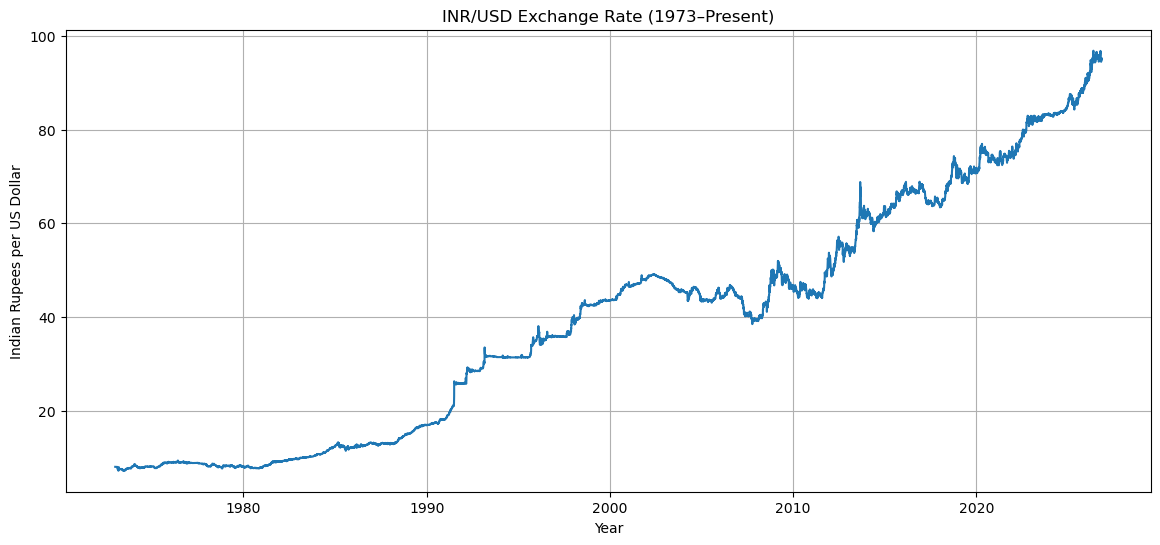

In [7]:
plt.figure(figsize=(14, 6))

plt.plot(
    exchange_rate["Date"],
    exchange_rate["INR_per_USD"]
)

plt.title("INR/USD Exchange Rate (1973–Present)")
plt.xlabel("Year")
plt.ylabel("Indian Rupees per US Dollar")
plt.grid(True)

plt.show()

In [8]:
exchange_rate.to_csv("INR_USD_FRED_Data.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [9]:
print("First date:", exchange_rate["Date"].min())
print("Last date:", exchange_rate["Date"].max())

print("Missing values:")
print(exchange_rate.isnull().sum())

print("Duplicate dates:", exchange_rate["Date"].duplicated().sum())

print("Summary statistics:")
display(exchange_rate["INR_per_USD"].describe())

First date: 1973-01-02 00:00:00
Last date: 2026-10-30 00:00:00
Missing values:
Date           0
INR_per_USD    0
dtype: int64
Duplicate dates: 0
Summary statistics:


count    13492.000000
mean        39.132207
std         24.995280
min          7.190000
25%         12.630000
50%         42.505000
75%         55.855000
max         96.820000
Name: INR_per_USD, dtype: float64

In [10]:
historical_data = {
    "Fiscal_Year": [
        "1947-48", "1948-49", "1949-50",
        "1950-51", "1951-52", "1952-53",
        "1953-54", "1954-55", "1955-56",
        "1956-57", "1957-58", "1958-59",
        "1959-60", "1960-61", "1961-62",
        "1962-63", "1963-64"
    ],

    "INR_per_USD": [
        3.3175, 3.3175, 4.074375,
        4.7750, 4.7815625, 4.7825,
        4.7625, 4.7778125, 4.789375,
        4.7922, 4.7832, 4.7654,
        4.7680, 4.7682, 4.7720,
        4.7720, 4.7829
    ]
}

historical_df = pd.DataFrame(historical_data)

display(historical_df)

,Fiscal_Year,INR_per_USD
0,1947-48,3.317500
1,1948-49,3.317500
2,1949-50,4.074375
3,1950-51,4.775000
4,1951-52,4.781562
5,1952-53,4.782500
6,1953-54,4.762500
7,1954-55,4.777812
8,1955-56,4.789375
9,1956-57,4.792200


In [11]:
# Extract calendar year
exchange_rate["Year"] = exchange_rate["Date"].dt.year

# Calculate annual average exchange rate
annual_fred = (
    exchange_rate.groupby("Year")["INR_per_USD"]
    .mean()
    .reset_index()
)

print("Annual FRED data:")
display(annual_fred.head(10))

Annual FRED data:


,Year,INR_per_USD
0,1973,7.654065
1,1974,8.028880
2,1975,8.408560
3,1976,8.971468
4,1977,8.768320
5,1978,8.197920
6,1979,8.156440
7,1980,7.886773
8,1981,8.680717
9,1982,9.484741


In [12]:
historical_df["Year"] = (
    historical_df["Fiscal_Year"].str[:4].astype(int)
)

print("RBI historical data:")
display(historical_df)

RBI historical data:


,Fiscal_Year,INR_per_USD,Year
0,1947-48,3.317500,1947
1,1948-49,3.317500,1948
2,1949-50,4.074375,1949
3,1950-51,4.775000,1950
4,1951-52,4.781562,1951
5,1952-53,4.782500,1952
6,1953-54,4.762500,1953
7,1954-55,4.777812,1954
8,1955-56,4.789375,1955
9,1956-57,4.792200,1956


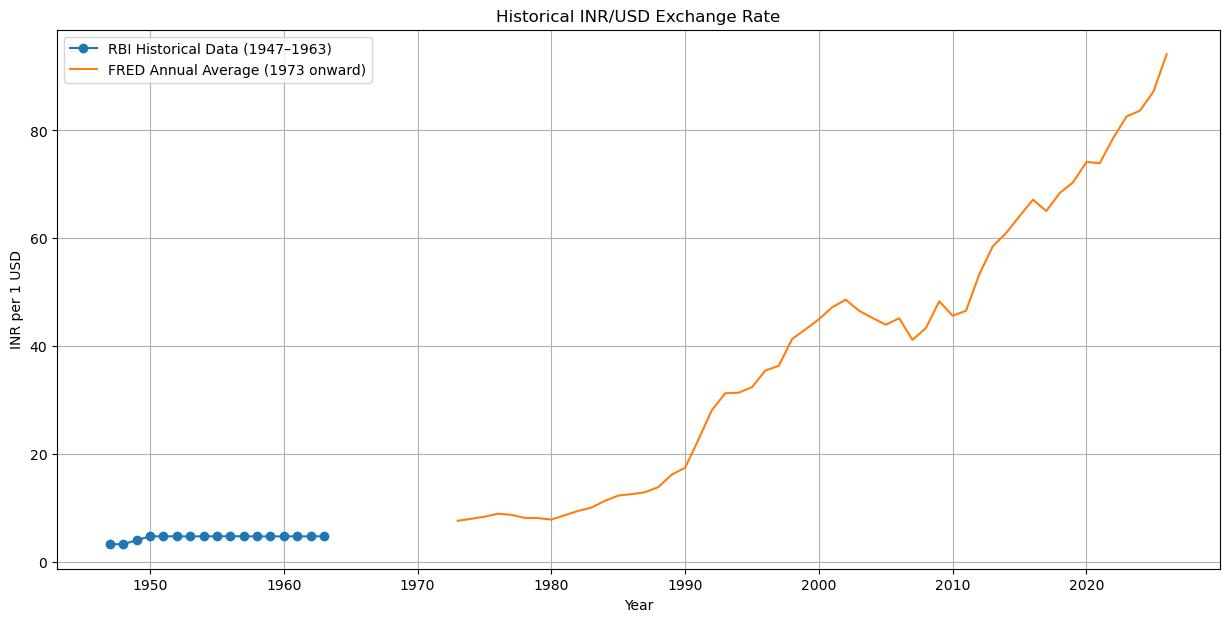

In [13]:
plt.figure(figsize=(15, 7))

# RBI historical data
plt.plot(
    historical_df["Year"],
    historical_df["INR_per_USD"],
    marker="o",
    label="RBI Historical Data (1947–1963)"
)

# FRED annual averages
plt.plot(
    annual_fred["Year"],
    annual_fred["INR_per_USD"],
    label="FRED Annual Average (1973 onward)"
)

plt.title("Historical INR/USD Exchange Rate")
plt.xlabel("Year")
plt.ylabel("INR per 1 USD")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
historical_df.to_csv("INR_USD_RBI_Historical.csv", index=False)

annual_fred.to_csv("INR_USD_Annual_FRED.csv", index=False)

print("Both annual datasets saved successfully!")

Both annual datasets saved successfully!


In [15]:
devaluation_events = pd.DataFrame({
    "Year": [1966, 1991, 1993, 2013, 2022],

    "Event": [
        "Major Rupee Devaluation",
        "1991 Balance of Payments Crisis",
        "Exchange Rate Unification",
        "Rupee Depreciation Episode",
        "Global Dollar Strength"
    ],

    "Main_Reason": [
        "Balance of payments difficulties and economic pressure",
        "Foreign exchange shortage and low foreign reserves",
        "Move toward a unified market-determined exchange rate",
        "US Federal Reserve tapering concerns and capital outflows",
        "Strong US dollar, global inflation and interest rate increases"
    ]
})

display(devaluation_events)

,Year,Event,Main_Reason
0,1966,Major Rupee Devaluation,Balance of payments difficulties and economic ...
1,1991,1991 Balance of Payments Crisis,Foreign exchange shortage and low foreign rese...
2,1993,Exchange Rate Unification,Move toward a unified market-determined exchan...
3,2013,Rupee Depreciation Episode,US Federal Reserve tapering concerns and capit...
4,2022,Global Dollar Strength,"Strong US dollar, global inflation and interes..."


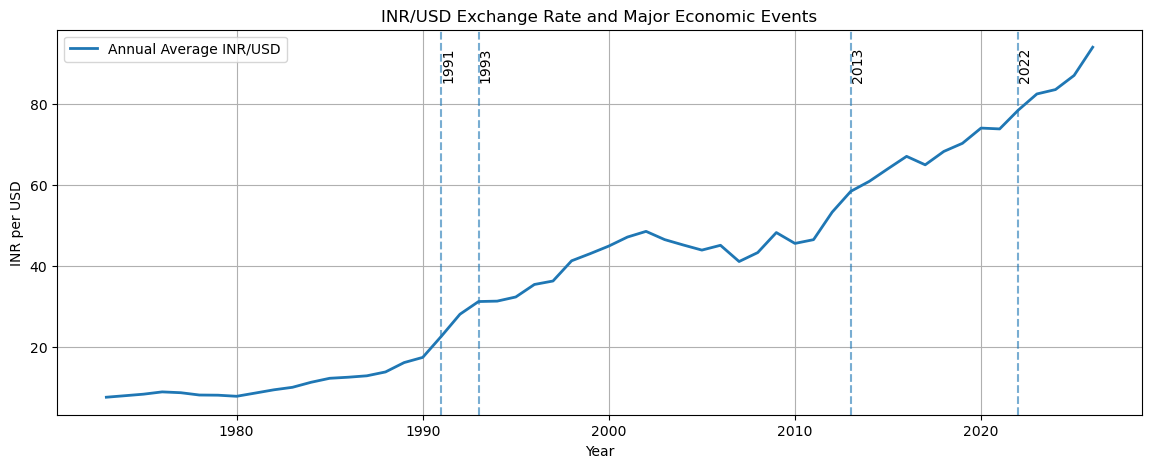

In [16]:
plt.figure(figsize=(14, 5))

plt.plot(
    annual_fred["Year"],
    annual_fred["INR_per_USD"],
    linewidth=2,
    label="Annual Average INR/USD"
)

for year in devaluation_events["Year"]:
    if year >= annual_fred["Year"].min():
        plt.axvline(year, linestyle="--", alpha=0.6)
        plt.text(
            year,
            annual_fred["INR_per_USD"].max(),
            str(year),
            rotation=90,
            verticalalignment="top"
        )

plt.title("INR/USD Exchange Rate and Major Economic Events")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.grid(True)
plt.legend()
plt.show()

In [17]:
annual_fred["Annual_Depreciation_%"] = (
    annual_fred["INR_per_USD"].pct_change() * 100
)

display(
    annual_fred[
        ["Year", "INR_per_USD", "Annual_Depreciation_%"]
    ].tail(20)
)

,Year,INR_per_USD,Annual_Depreciation_%
34,2007,41.177402,-8.871441
35,2008,43.385913,5.363406
36,2009,48.332381,11.401093
37,2010,45.650743,-5.548326
38,2011,46.578167,2.031565
39,2012,53.374343,14.590904
40,2013,58.514861,9.631065
41,2014,60.995252,4.238909
42,2015,64.107251,5.102035
43,2016,67.157171,4.757528


In [18]:
# Find the 10 years with the highest annual depreciation
top_depreciation_years = (
    annual_fred.dropna()
    .nlargest(10, "Annual_Depreciation_%")
)

display(
    top_depreciation_years[
        ["Year", "INR_per_USD", "Annual_Depreciation_%"]
    ]
)

,Year,INR_per_USD,Annual_Depreciation_%
18,1991,22.711647,29.838643
19,1992,28.155817,23.970830
16,1989,16.213108,16.645074
39,2012,53.374343,14.590904
25,1998,41.356107,13.726562
11,1984,11.346520,12.296157
36,2009,48.332381,11.401093
20,1993,31.291076,11.135386
8,1981,8.680717,10.066782
40,2013,58.514861,9.631065


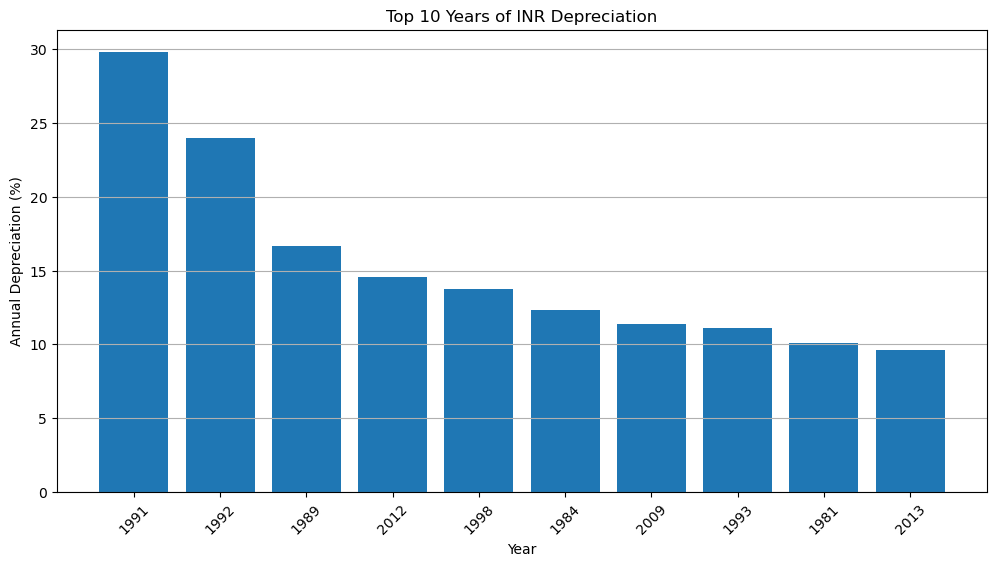

In [19]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_depreciation_years["Year"].astype(str),
    top_depreciation_years["Annual_Depreciation_%"]
)

plt.title("Top 10 Years of INR Depreciation")
plt.xlabel("Year")
plt.ylabel("Annual Depreciation (%)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

In [20]:
selected_years = [1973, 1980, 1991, 2000, 2010, 2020, 2024]

period_comparison = annual_fred[
    annual_fred["Year"].isin(selected_years)
].copy()

display(period_comparison)

,Year,INR_per_USD,Annual_Depreciation_%
0,1973,7.654065,NaN
7,1980,7.886773,-3.306186
18,1991,22.711647,29.838643
27,2000,44.997476,4.336165
37,2010,45.650743,-5.548326
47,2020,74.142920,5.350002
51,2024,83.656574,1.314908


In [21]:
top_depreciation_years.to_csv(
    "Top_INR_Depreciation_Years.csv",
    index=False
)

devaluation_events.to_csv(
    "INR_Devaluation_Events.csv",
    index=False
)

print("Analysis files saved successfully!")

Analysis files saved successfully!


In [22]:
# Convert daily observations into monthly averages
monthly = (
    exchange_rate
    .set_index("Date")["INR_per_USD"]
    .resample("MS")
    .mean()
    .dropna()
)

# Keep observations through August 2026
monthly = monthly.loc[: "2026-08-01"]

print("First month:", monthly.index.min())
print("Last month:", monthly.index.max())
print("Number of monthly observations:", len(monthly))

display(monthly.tail(12))

First month: 1973-01-01 00:00:00
Last month: 2026-08-01 00:00:00
Number of monthly observations: 644


Date
2025-09-01    88.321429
2025-10-01    88.369091
2025-11-01    88.844444
2025-12-01    90.035000
2026-01-01    90.902500
2026-02-01    90.745789
2026-03-01    92.818182
2026-04-01    93.480455
2026-05-01    95.533500
2026-06-01    94.960000
2026-07-01    95.857273
2026-08-01    95.444286
Freq: MS, Name: INR_per_USD, dtype: float64

In [23]:
last_actual_rate = monthly.iloc[-1]

print("Last observed month:", monthly.index[-1].strftime("%B %Y"))
print("August 2026 INR/USD rate:", round(last_actual_rate, 4))

Last observed month: August 2026
August 2026 INR/USD rate: 95.4443


In [24]:
# Build ARIMA model
arima_model = ARIMA(
    monthly,
    order=(1, 1, 1)
)

arima_result = arima_model.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:            INR_per_USD   No. Observations:                  644
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -649.845
Date:                Wed, 04 Nov 2026   AIC                           1305.690
Time:                        20:58:00   BIC                           1319.089
Sample:                    01-01-1973   HQIC                          1310.890
                         - 08-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2528      0.093      2.707      0.007       0.070       0.436
ma.L1          0.0078      0.102      0.076      0.939      -0.192       0.208
sigma2         0.4419      0.012     37.438      0.0

In [25]:
# Forecast September 2026 to August 2050
forecast_steps = 288

arima_forecast = arima_result.get_forecast(
    steps=forecast_steps
)

forecast_dates = pd.date_range(
    start="2026-09-01",
    periods=forecast_steps,
    freq="MS"
)

forecast_df = pd.DataFrame({
    "Date": forecast_dates,
    "ARIMA_Forecast": arima_forecast.predicted_mean.to_numpy()
})

display(forecast_df.head())
display(forecast_df.tail())

,Date,ARIMA_Forecast
0,2026-09-01,95.334851
1,2026-10-01,95.307188
2,2026-11-01,95.300195
3,2026-12-01,95.298428
4,2027-01-01,95.297981


,Date,ARIMA_Forecast
283,2050-04-01,95.29783
284,2050-05-01,95.29783
285,2050-06-01,95.29783
286,2050-07-01,95.29783
287,2050-08-01,95.29783


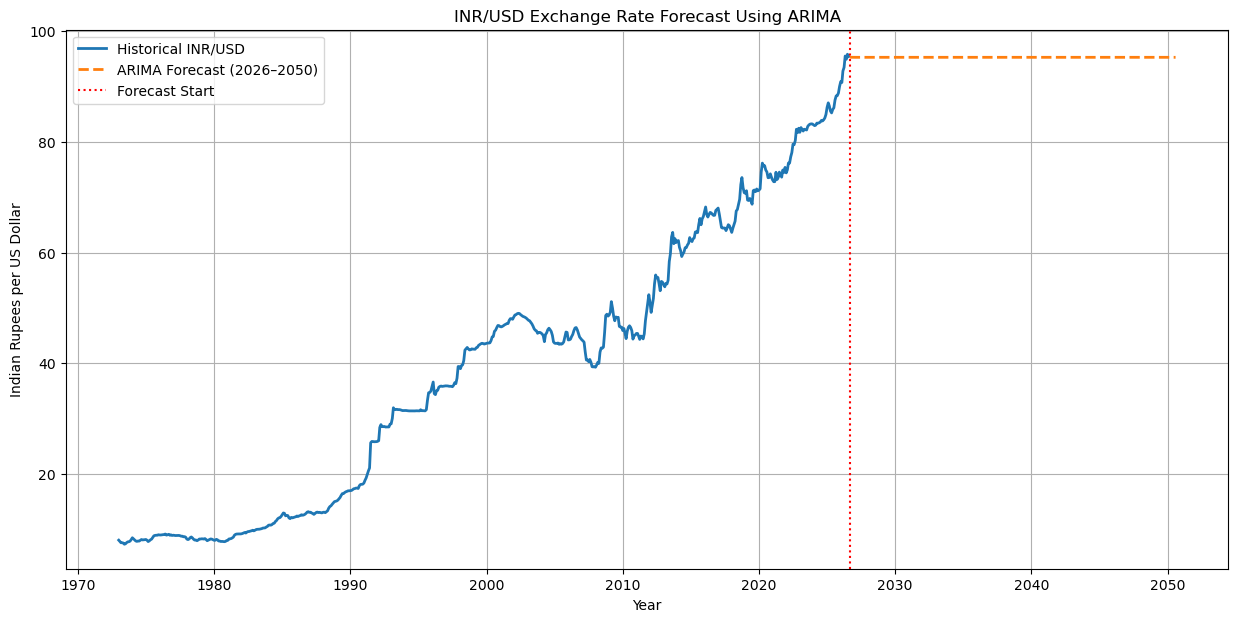

In [26]:
plt.figure(figsize=(15, 7))

# Historical exchange rates
plt.plot(
    monthly.index,
    monthly.values,
    label="Historical INR/USD",
    linewidth=2
)

# Forecasted exchange rates
plt.plot(
    forecast_df["Date"],
    forecast_df["ARIMA_Forecast"],
    label="ARIMA Forecast (2026–2050)",
    linestyle="--",
    linewidth=2
)

plt.axvline(
    pd.Timestamp("2026-09-01"),
    color="red",
    linestyle=":",
    label="Forecast Start"
)

plt.title("INR/USD Exchange Rate Forecast Using ARIMA")
plt.xlabel("Year")
plt.ylabel("Indian Rupees per US Dollar")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
forecast_df["Year"] = forecast_df["Date"].dt.year

selected_forecast_years = [2030, 2035, 2040, 2045, 2050]

forecast_summary = forecast_df[
    (forecast_df["Year"].isin(selected_forecast_years))
    & (forecast_df["Date"].dt.month == 8)
]

display(
    forecast_summary[
        ["Year", "ARIMA_Forecast"]
    ].round(2)
)

,Year,ARIMA_Forecast
47,2030,95.3
107,2035,95.3
167,2040,95.3
227,2045,95.3
287,2050,95.3


In [28]:
# Prepare data for Linear Regression

monthly_df = monthly.reset_index()
monthly_df.columns = ["Date", "INR_per_USD"]

# Create a numerical time index
monthly_df["Time_Index"] = np.arange(len(monthly_df))

# Define features and target
X = monthly_df[["Time_Index"]]
y = monthly_df["INR_per_USD"]

# Train the model
lr_model = LinearRegression()
lr_model.fit(X, y)

print("Linear Regression model trained successfully!")
print("Intercept:", lr_model.intercept_)
print("Monthly slope:", lr_model.coef_[0])

Linear Regression model trained successfully!
Intercept: -2.973658538595707
Monthly slope: 0.1304470103475271


In [29]:
# Create future time indices
future_time_index = np.arange(
    len(monthly_df),
    len(monthly_df) + 288
)

# Generate predictions
lr_forecast = lr_model.predict(
    future_time_index.reshape(-1, 1)
)

# Add predictions to forecast dataframe
forecast_df["Linear_Regression_Forecast"] = lr_forecast

display(forecast_df.head())
display(forecast_df.tail())

/opt/anaconda3/lib/python3.11/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,Date,ARIMA_Forecast,Year,Linear_Regression_Forecast
0,2026-09-01,95.334851,2026,81.034216
1,2026-10-01,95.307188,2026,81.164663
2,2026-11-01,95.300195,2026,81.295110
3,2026-12-01,95.298428,2026,81.425557
4,2027-01-01,95.297981,2027,81.556004


,Date,ARIMA_Forecast,Year,Linear_Regression_Forecast
283,2050-04-01,95.29783,2050,117.950720
284,2050-05-01,95.29783,2050,118.081167
285,2050-06-01,95.29783,2050,118.211614
286,2050-07-01,95.29783,2050,118.342061
287,2050-08-01,95.29783,2050,118.472508


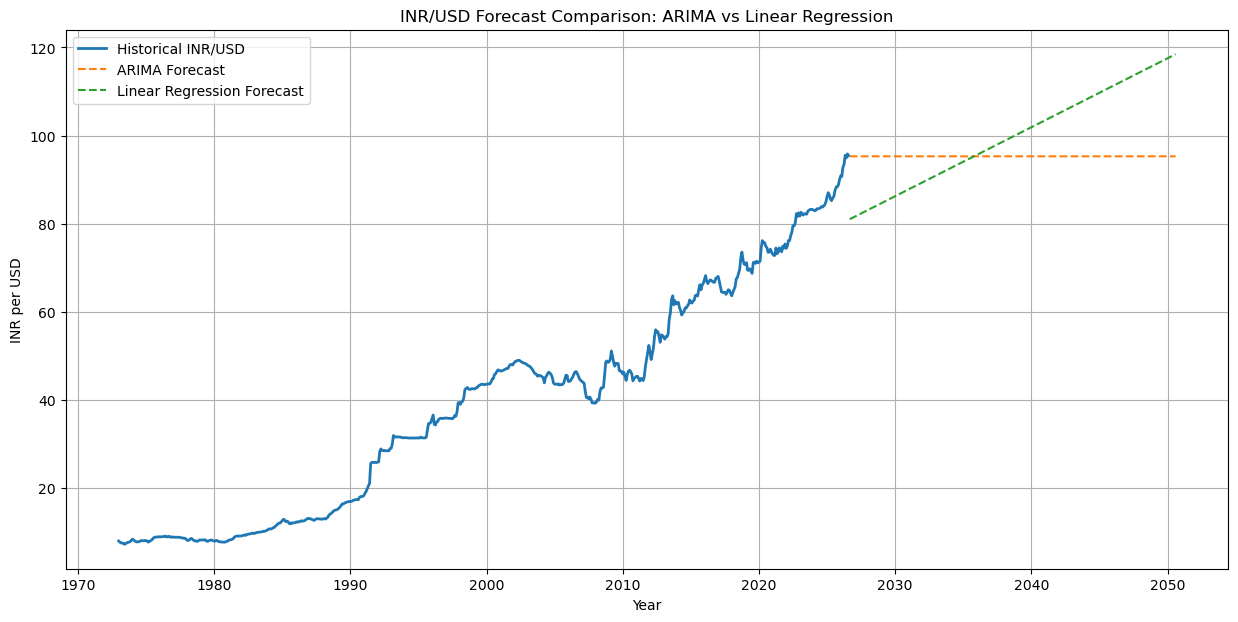

In [30]:
plt.figure(figsize=(15, 7))

# Historical data
plt.plot(
    monthly.index,
    monthly.values,
    label="Historical INR/USD",
    linewidth=2
)

# ARIMA forecast
plt.plot(
    forecast_df["Date"],
    forecast_df["ARIMA_Forecast"],
    label="ARIMA Forecast",
    linestyle="--"
)

# Linear Regression forecast
plt.plot(
    forecast_df["Date"],
    forecast_df["Linear_Regression_Forecast"],
    label="Linear Regression Forecast",
    linestyle="--"
)

plt.title("INR/USD Forecast Comparison: ARIMA vs Linear Regression")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(True)

plt.show()

In [31]:
# Get August 2050 predictions
forecast_2050 = forecast_df[
    forecast_df["Date"] == "2050-08-01"
]

display(
    forecast_2050[
        [
            "Date",
            "ARIMA_Forecast",
            "Linear_Regression_Forecast"
        ]
    ].round(2)
)

,Date,ARIMA_Forecast,Linear_Regression_Forecast
287,2050-08-01,95.3,118.47


In [32]:
# Starting exchange rate
base_rate = last_actual_rate

# Number of years since August 2026
years_ahead = (
    (forecast_df["Date"].dt.year - 2026)
    + (forecast_df["Date"].dt.month - 8) / 12
)

# Calculate scenario projections
forecast_df["Low_Depreciation"] = (
    base_rate * (1.01 ** years_ahead)
)

forecast_df["Moderate_Depreciation"] = (
    base_rate * (1.025 ** years_ahead)
)

forecast_df["High_Depreciation"] = (
    base_rate * (1.04 ** years_ahead)
)

display(forecast_df.tail())

,Date,ARIMA_Forecast,Year,Linear_Regression_Forecast,Low_Depreciation,Moderate_Depreciation,High_Depreciation
283,2050-04-01,95.29783,2050,117.950720,120.787626,171.217472,241.475067
284,2050-05-01,95.29783,2050,118.081167,120.887824,171.570152,242.265594
285,2050-06-01,95.29783,2050,118.211614,120.988105,171.923558,243.058708
286,2050-07-01,95.29783,2050,118.342061,121.088469,172.277692,243.854419
287,2050-08-01,95.29783,2050,118.472508,121.188917,172.632556,244.652735


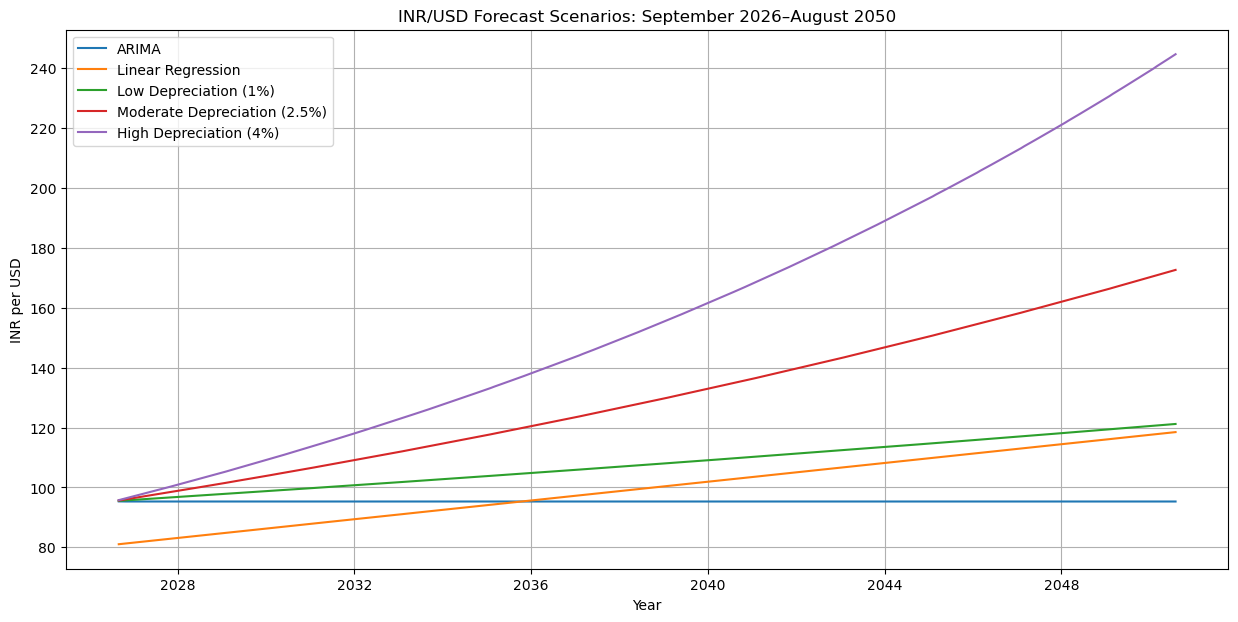

In [33]:
plt.figure(figsize=(15, 7))

plt.plot(
    forecast_df["Date"],
    forecast_df["ARIMA_Forecast"],
    label="ARIMA"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Linear_Regression_Forecast"],
    label="Linear Regression"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Low_Depreciation"],
    label="Low Depreciation (1%)"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Moderate_Depreciation"],
    label="Moderate Depreciation (2.5%)"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["High_Depreciation"],
    label="High Depreciation (4%)"
)

plt.title("INR/USD Forecast Scenarios: September 2026–August 2050")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(True)

plt.show()

In [34]:
comparison_2050 = forecast_df.loc[
    forecast_df["Date"] == pd.Timestamp("2050-08-01"),
    [
        "ARIMA_Forecast",
        "Linear_Regression_Forecast",
        "Low_Depreciation",
        "Moderate_Depreciation",
        "High_Depreciation"
    ]
].T

comparison_2050.columns = ["August 2050 INR/USD"]

display(comparison_2050.round(2))

,August 2050 INR/USD
ARIMA_Forecast,95.30
Linear_Regression_Forecast,118.47
Low_Depreciation,121.19
Moderate_Depreciation,172.63
High_Depreciation,244.65


In [35]:
forecast_df.to_csv(
    "INR_USD_Forecast_2026_2050.csv",
    index=False
)

print("Forecast results saved successfully!")

Forecast results saved successfully!


In [36]:
# Split monthly data
train = monthly.loc[: "2018-12-01"]
test = monthly.loc["2019-01-01":"2024-08-01"]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training ends:", train.index.max())
print("Testing starts:", test.index.min())
print("Testing ends:", test.index.max())

Training observations: 552
Testing observations: 68
Training ends: 2018-12-01 00:00:00
Testing starts: 2019-01-01 00:00:00
Testing ends: 2024-08-01 00:00:00


In [37]:
# Train ARIMA using training data only
arima_test_model = ARIMA(
    train,
    order=(1, 1, 1)
)

arima_test_result = arima_test_model.fit()

# Forecast the testing period
arima_predictions = arima_test_result.forecast(
    steps=len(test)
)

# Calculate errors
arima_mae = mean_absolute_error(
    test, arima_predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(test, arima_predictions)
)

print("ARIMA MAE:", round(arima_mae, 4))
print("ARIMA RMSE:", round(arima_rmse, 4))

ARIMA MAE: 6.2093
ARIMA RMSE: 7.7054


In [38]:
# Prepare training time index
X_train = np.arange(len(train)).reshape(-1, 1)
y_train = train.values

# Prepare testing time index
X_test = np.arange(
    len(train),
    len(train) + len(test)
).reshape(-1, 1)

# Train Linear Regression
lr_test_model = LinearRegression()
lr_test_model.fit(X_train, y_train)

# Predict test period
lr_predictions = lr_test_model.predict(X_test)

# Calculate errors
lr_mae = mean_absolute_error(test, lr_predictions)

lr_rmse = np.sqrt(
    mean_squared_error(test, lr_predictions)
)

print("Linear Regression MAE:", round(lr_mae, 4))
print("Linear Regression RMSE:", round(lr_rmse, 4))

Linear Regression MAE: 7.6559
Linear Regression RMSE: 8.1265


In [39]:
accuracy_comparison = pd.DataFrame({
    "Model": ["ARIMA", "Linear Regression"],
    "MAE": [arima_mae, lr_mae],
    "RMSE": [arima_rmse, lr_rmse]
})

display(accuracy_comparison.round(4))

,Model,MAE,RMSE
0,ARIMA,6.2093,7.7054
1,Linear Regression,7.6559,8.1265


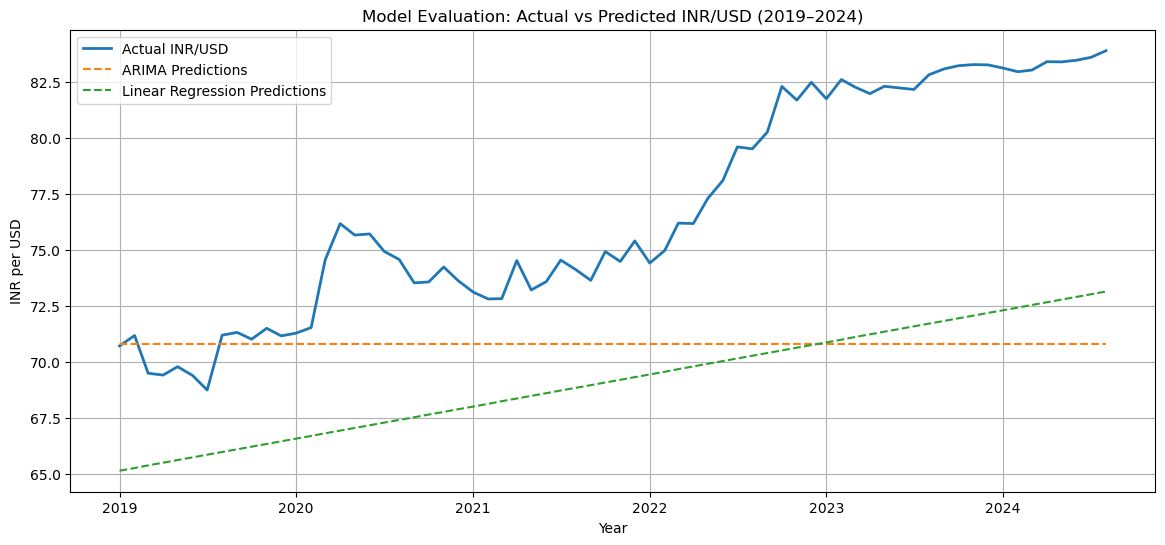

In [40]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index, test.values,
    label="Actual INR/USD",
    linewidth=2
)

plt.plot(
    test.index, arima_predictions,
    label="ARIMA Predictions",
    linestyle="--"
)

plt.plot(
    test.index, lr_predictions,
    label="Linear Regression Predictions",
    linestyle="--"
)

plt.title("Model Evaluation: Actual vs Predicted INR/USD (2019–2024)")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(True)
plt.show()

In [41]:
accuracy_comparison.to_csv(
    "INR_USD_Model_Accuracy.csv",
    index=False
)

print("Model evaluation saved successfully!")

Model evaluation saved successfully!


The ARIMA (1,1,1) model achieved an MAE of 6.2093 and an RMSE of 7.7054, while Linear Regression produced an MAE of 7.6559 and an RMSE of 8.1265. ARIMA therefore demonstrated better predictive accuracy during the January 2019–August 2024 testing period. However, these results are based on one historical test window and do not establish long-term forecast reliability. The forecasts through August 2050 should be interpreted cautiously due to economic uncertainty.

In [42]:
best_model = accuracy_comparison.loc[
    accuracy_comparison["RMSE"].idxmin(), "Model"
]

mae_improvement = (
    (lr_mae - arima_mae) / lr_mae
) * 100

rmse_improvement = (
    (lr_rmse - arima_rmse) / lr_rmse
) * 100

print("Best performing model:", best_model)
print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

Best performing model: ARIMA
MAE improvement: 18.90%
RMSE improvement: 5.18%


In [43]:
# Use complete calendar years through 2024
stability_df = annual_fred[
    (annual_fred["Year"] >= 1974) &
    (annual_fred["Year"] <= 2024)
].copy()

# Assign each year to a decade
stability_df["Decade"] = (
    stability_df["Year"] // 10 * 10
)

# Calculate decade-level statistics
decade_stability = (
    stability_df.groupby("Decade")
    .agg(
        Average_INR_per_USD=("INR_per_USD", "mean"),
        Exchange_Rate_Volatility=("Annual_Depreciation_%", "std"),
        Average_Annual_Change=("Annual_Depreciation_%", "mean")
    )
    .reset_index()
)

display(decade_stability.round(2))

,Decade,Average_INR_per_USD,Exchange_Rate_Volatility,Average_Annual_Change
0,1970,8.42,5.11,1.17
1,1980,11.55,5.63,7.25
2,1990,31.98,9.62,10.64
3,2000,45.48,5.90,1.30
4,2010,60.02,5.71,3.97
5,2020,78.58,2.86,3.55


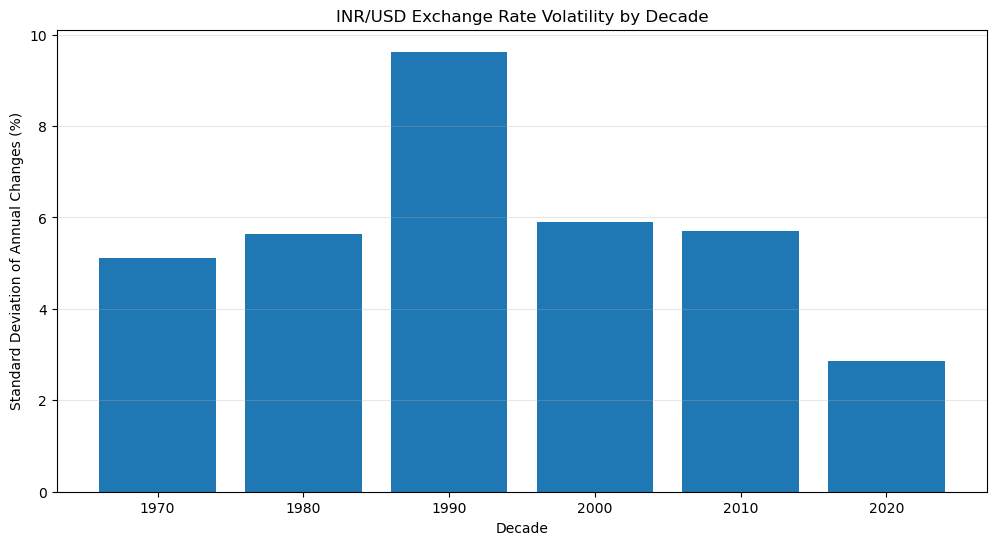

In [44]:
plt.figure(figsize=(12, 6))

plt.bar(
    decade_stability["Decade"].astype(str),
    decade_stability["Exchange_Rate_Volatility"]
)

plt.title("INR/USD Exchange Rate Volatility by Decade")
plt.xlabel("Decade")
plt.ylabel("Standard Deviation of Annual Changes (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [45]:
decade_stability.to_csv(
    "INR_USD_Decade_Stability.csv",
    index=False
)

print("Monetary stability analysis saved successfully!")

Monetary stability analysis saved successfully!


In [46]:
import requests
import pandas as pd
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Create a session with automatic retries
session = requests.Session()

retry_strategy = Retry(
    total=3,
    backoff_factor=2,
    status_forcelist=[429, 500, 502, 503, 504]
)

adapter = HTTPAdapter(max_retries=retry_strategy)

session.mount("https://", adapter)

# World Bank inflation indicator
indicator = "FP.CPI.TOTL.ZG"

all_data = []

for country in ["IND", "USA"]:

    url = (
        f"https://api.worldbank.org/v2/country/{country}/"
        f"indicator/{indicator}"
    )

    try:
        response = session.get(
            url,
            params={
                "format": "json",
                "per_page": 200,
                "date": "1960:2024"
            },
            timeout=90
        )

        response.raise_for_status()
        records = response.json()[1]

        for item in records:
            if item["value"] is not None:
                all_data.append({
                    "Country": item["country"]["value"],
                    "Country_Code": country,
                    "Year": int(item["date"]),
                    "Inflation_Rate": item["value"]
                })

        print(f"{country} data downloaded successfully!")

    except requests.exceptions.RequestException as e:
        print(f"Download failed for {country}: {e}")

inflation_df = pd.DataFrame(all_data)

if inflation_df.empty:
    print("No data downloaded. Please check your internet connection.")
else:
    inflation_df = inflation_df.sort_values(
        ["Country_Code", "Year"]
    )

    display(inflation_df.head(10))

    print("Total observations:", len(inflation_df))

IND data downloaded successfully!
USA data downloaded successfully!


,Country,Country_Code,Year,Inflation_Rate
64,India,IND,1960,1.779878
63,India,IND,1961,1.695213
62,India,IND,1962,3.632215
61,India,IND,1963,2.946161
60,India,IND,1964,13.355261
59,India,IND,1965,9.474759
58,India,IND,1966,10.801848
57,India,IND,1967,13.062202
56,India,IND,1968,3.237412
55,India,IND,1969,-0.584137


Total observations: 130


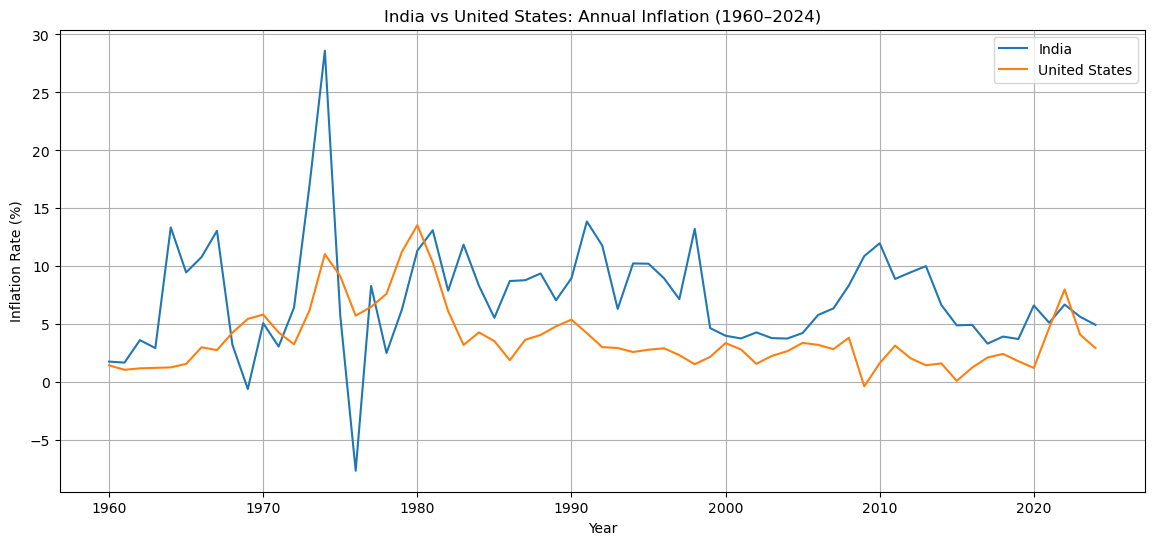

In [47]:
plt.figure(figsize=(14, 6))

for country, label in [
    ("IND", "India"),
    ("USA", "United States")
]:
    subset = inflation_df[
        inflation_df["Country_Code"] == country
    ]

    plt.plot(
        subset["Year"],
        subset["Inflation_Rate"],
        label=label
    )

plt.title("India vs United States: Annual Inflation (1960–2024)")
plt.xlabel("Year")
plt.ylabel("Inflation Rate (%)")
plt.legend()
plt.grid(True)
plt.show()

In [48]:
inflation_comparison = (
    inflation_df.groupby("Country_Code")
    .agg(
        Average_Inflation=("Inflation_Rate", "mean"),
        Inflation_Volatility=("Inflation_Rate", "std"),
        Highest_Inflation=("Inflation_Rate", "max"),
        Lowest_Inflation=("Inflation_Rate", "min"),
        Years_Observed=("Inflation_Rate", "count")
    )
    .round(2)
)

display(inflation_comparison)

,Average_Inflation,Inflation_Volatility,Highest_Inflation,Lowest_Inflation,Years_Observed
Country_Code,,,,,
IND,7.30,4.81,28.60,-7.63,65
USA,3.76,2.74,13.55,-0.36,65


In [49]:
inflation_df.to_csv(
    "India_US_Inflation_1960_2024.csv",
    index=False
)

inflation_comparison.to_csv(
    "India_US_Inflation_Comparison.csv"
)

print("Inflation comparison saved successfully!")

Inflation comparison saved successfully!


### India vs. United States: Monetary Stability Analysis

Based on the World Bank inflation data analyzed for 1960–2024, India recorded an average annual inflation rate of 7.30%, compared with 3.76% in the United States. India's inflation volatility was 4.81 percentage points, while the United States recorded 2.74 percentage points.

These findings indicate that the United States experienced lower and more stable consumer-price inflation over the observed period. India's relatively higher inflation may have contributed to long-term depreciation pressures on the Indian rupee against the US dollar. However, inflation differences alone cannot fully explain exchange-rate movements, which are also influenced by monetary policy, international trade, capital flows, and global economic conditions.

In [50]:
billionaire_df = pd.DataFrame({
    "Year": [2023, 2024],
    "India": [169, 200],
    "USA": [735, 813]
})

display(billionaire_df)

,Year,India,USA
0,2023,169,735
1,2024,200,813


In [51]:
india_growth = (
    (200 - 169) / 169
) * 100

usa_growth = (
    (813 - 735) / 735
) * 100

print(f"India billionaire growth: {india_growth:.2f}%")
print(f"USA billionaire growth: {usa_growth:.2f}%")

India billionaire growth: 18.34%
USA billionaire growth: 10.61%


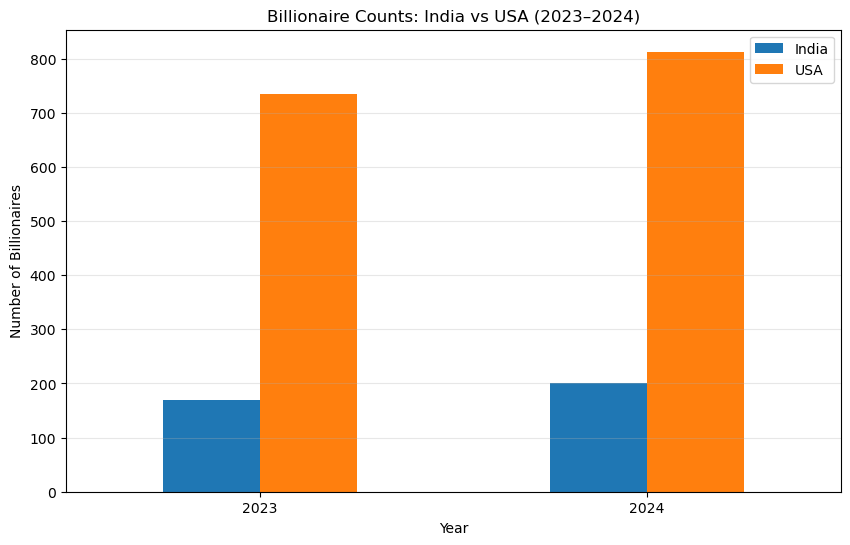

In [52]:
billionaire_df.plot(
    x="Year",
    y=["India", "USA"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("Billionaire Counts: India vs USA (2023–2024)")
plt.xlabel("Year")
plt.ylabel("Number of Billionaires")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [53]:
billionaire_df.to_csv(
    "India_US_Billionaires_2023_2024.csv",
    index=False
)

print("Billionaire comparison saved successfully!")

Billionaire comparison saved successfully!


In [54]:
happiness_df = pd.DataFrame({
    "Country": ["India", "United States"],
    "Happiness_Score": [4.054, 6.725],
    "Global_Rank": [126, 23],
    "Report_Year": [2024, 2024]
})

display(happiness_df)

,Country,Happiness_Score,Global_Rank,Report_Year
0,India,4.054,126,2024
1,United States,6.725,23,2024


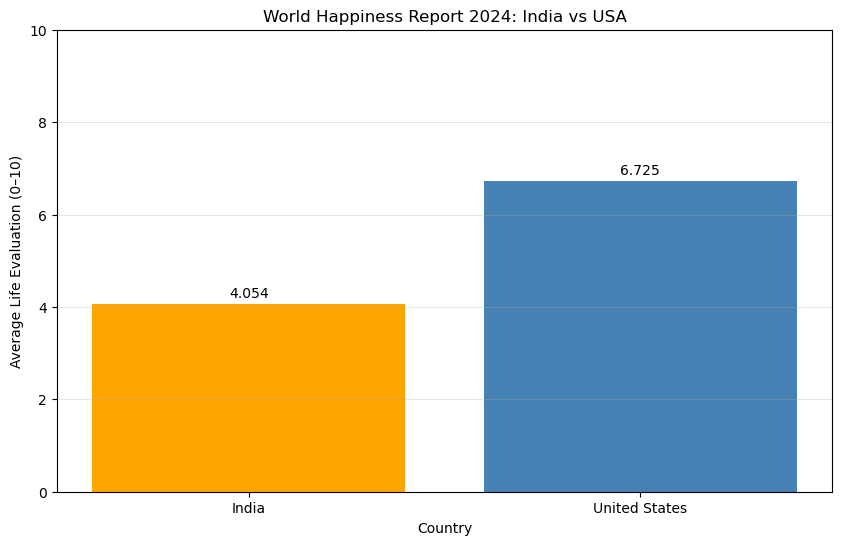

In [55]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    happiness_df["Country"],
    happiness_df["Happiness_Score"],
    color=["orange", "steelblue"]
)

plt.title("World Happiness Report 2024: India vs USA")
plt.xlabel("Country")
plt.ylabel("Average Life Evaluation (0–10)")
plt.ylim(0, 10)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.15,
        f"{bar.get_height():.3f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()

In [56]:
india_score = happiness_df.loc[
    happiness_df["Country"] == "India",
    "Happiness_Score"
].iloc[0]

usa_score = happiness_df.loc[
    happiness_df["Country"] == "United States",
    "Happiness_Score"
].iloc[0]

difference = usa_score - india_score

print(f"India Happiness Score: {india_score:.3f}")
print(f"USA Happiness Score: {usa_score:.3f}")
print(f"Difference: {difference:.3f} points")

India Happiness Score: 4.054
USA Happiness Score: 6.725
Difference: 2.671 points


In [57]:
happiness_df.to_csv(
    "India_US_Happiness_2024.csv",
    index=False
)

print("Happiness comparison saved successfully!")

Happiness comparison saved successfully!


### India vs. United States: Happiness Comparison

According to the World Happiness Report 2024, the United States ranked 23rd globally with an average life evaluation score of 6.725, while India ranked 126th with a score of 4.054. The difference between the countries was 2.671 points.

These results indicate that surveyed respondents in the United States reported higher average life satisfaction than respondents in India during 2021–2023. However, happiness rankings reflect multiple social and economic influences, including social support, health, freedom, and economic circumstances.

The comparison also demonstrates that economic growth and billionaire wealth do not necessarily translate directly into higher average life satisfaction.

**Source:** World Happiness Report 2024, Chapter 2.

## Final Project Summary and Findings

### 1. Historical INR/USD Exchange Rate Analysis

This project examined the historical movement of the Indian rupee against the US dollar, covering the period from 1947 onward. The analysis considered major events, including the 1966 devaluation, the 1991 balance-of-payments crisis, the 1993 exchange-rate unification, and depreciation episodes in 2013 and 2022.

The historical analysis showed the long-term depreciation of the Indian rupee against the US dollar. However, the early historical dataset and missing years still require source verification before the full 1947–2024 analysis can be considered complete.

### 2. INR/USD Exchange Rate Forecasting (2026–2050)

Two statistical models were developed to forecast the INR/USD exchange rate from September 2026 to August 2050.

| Forecasting model | August 2050 prediction |
|---|---:|
| ARIMA (1,1,1) | ₹95.30 |
| Linear Regression | ₹118.47 |

The models produced different long-term predictions, reflecting their different assumptions about exchange-rate behavior.

### 3. Forecast Model Evaluation

The models were evaluated using historical observations from January 2019 through August 2024.

| Metric | ARIMA | Linear Regression |
|---|---:|---:|
| MAE | 6.2093 | 7.6559 |
| RMSE | 7.7054 | 8.1265 |

ARIMA achieved lower MAE and RMSE, indicating better performance during the selected testing period. However, performance on one historical period does not guarantee accuracy through 2050.

### 4. India vs. United States: Inflation

| Metric | India | United States |
|---|---:|---:|
| Average annual inflation | 7.30% | 3.76% |
| Inflation volatility | 4.81 | 2.74 |

The United States experienced lower average consumer-price inflation and less variation in annual inflation rates over the analyzed period.

### 5. Billionaire Growth (2023–2024)

India's billionaire count increased from 169 to 200, while the United States increased from 735 to 813.

India experienced approximately 18.34% growth, compared with 10.61% in the United States. Although India's percentage growth was higher, the United States maintained a substantially larger billionaire population.

### 6. World Happiness Report 2024

India recorded a happiness score of 4.054 and ranked 126th, while the United States scored 6.725 and ranked 23rd.

The difference of 2.671 points indicates higher average reported life evaluations in the United States during the survey period.

### 7. Overall Conclusion

The findings suggest

In [58]:
# Verify the main datasets exist

datasets = {
    "Daily INR/USD": exchange_rate,
    "Historical RBI": historical_df,
    "Annual INR/USD": annual_fred,
    "Monthly INR/USD": monthly,
    "Forecast Results": forecast_df,
    "Model Accuracy": accuracy_comparison,
    "Inflation Data": inflation_df,
    "Billionaire Data": billionaire_df,
    "Happiness Data": happiness_df
}

for name, data in datasets.items():
    print(f"{name}: {len(data)} observations")

print("\nNotebook dataset check completed!")

Daily INR/USD: 13492 observations
Historical RBI: 17 observations
Annual INR/USD: 54 observations
Monthly INR/USD: 644 observations
Forecast Results: 288 observations
Model Accuracy: 2 observations
Inflation Data: 130 observations
Billionaire Data: 2 observations
Happiness Data: 2 observations

Notebook dataset check completed!


In [59]:
# Check historical coverage

print("RBI historical data:")
print("First year:", historical_df["Year"].min())
print("Last year:", historical_df["Year"].max())

print("\nFRED historical data:")
print("First year:", annual_fred["Year"].min())
print("Last year:", annual_fred["Year"].max())

# Identify missing years from 1947 through 2024
available_years = set(historical_df["Year"]).union(
    set(annual_fred["Year"])
)

missing_years = sorted(
    set(range(1947, 2025)) - available_years
)

print("\nMissing years:")
print(missing_years)

RBI historical data:
First year: 1947
Last year: 1963

FRED historical data:
First year: 1973
Last year: 2026

Missing years:
[1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972]


In [60]:
coverage_df = pd.DataFrame({
    "Year": range(1947, 2025)
})

coverage_df["Data_Status"] = coverage_df["Year"].apply(
    lambda year: (
        "RBI - Verification Required"
        if year in historical_df["Year"].values
        else "FRED - Available"
        if year in annual_fred["Year"].values
        else "Missing"
    )
)

display(coverage_df)

print("\nCoverage summary:")
print(coverage_df["Data_Status"].value_counts())

,Year,Data_Status
0,1947,RBI - Verification Required
1,1948,RBI - Verification Required
2,1949,RBI - Verification Required
3,1950,RBI - Verification Required
4,1951,RBI - Verification Required
...,...,...
73,2020,FRED - Available
74,2021,FRED - Available
75,2022,FRED - Available
76,2023,FRED - Available



Coverage summary:
Data_Status
FRED - Available               52
RBI - Verification Required    17
Missing                         9
Name: count, dtype: int64


In [61]:
# Penn World Table 11.0 via FRED
historical_url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=XRNCUSINA618NRUG"
)

pwt_df = pd.read_csv(historical_url)

pwt_df.columns = ["Date", "INR_per_USD"]
pwt_df["Date"] = pd.to_datetime(pwt_df["Date"])

pwt_df["INR_per_USD"] = pd.to_numeric(
    pwt_df["INR_per_USD"],
    errors="coerce"
)

pwt_df["Year"] = pwt_df["Date"].dt.year

display(
    pwt_df[
        pwt_df["Year"].between(1964, 1972)
    ]
)

,Date,INR_per_USD,Year
14,1964-01-01,4.761900,1964
15,1965-01-01,4.761900,1965
16,1966-01-01,6.359125,1966
17,1967-01-01,7.500000,1967
18,1968-01-01,7.500000,1968
19,1969-01-01,7.500000,1969
20,1970-01-01,7.500000,1970
21,1971-01-01,7.491935,1971
22,1972-01-01,7.594468,1972


In [62]:
missing_historical = pwt_df[
    pwt_df["Year"].between(1964, 1972)
].copy()

missing_historical["Source"] = (
    "Penn World Table 11.0 via FRED"
)

display(missing_historical)

,Date,INR_per_USD,Year,Source
14,1964-01-01,4.761900,1964,Penn World Table 11.0 via FRED
15,1965-01-01,4.761900,1965,Penn World Table 11.0 via FRED
16,1966-01-01,6.359125,1966,Penn World Table 11.0 via FRED
17,1967-01-01,7.500000,1967,Penn World Table 11.0 via FRED
18,1968-01-01,7.500000,1968,Penn World Table 11.0 via FRED
19,1969-01-01,7.500000,1969,Penn World Table 11.0 via FRED
20,1970-01-01,7.500000,1970,Penn World Table 11.0 via FRED
21,1971-01-01,7.491935,1971,Penn World Table 11.0 via FRED
22,1972-01-01,7.594468,1972,Penn World Table 11.0 via FRED


In [63]:
combined_years = (
    set(historical_df["Year"])
    | set(missing_historical["Year"])
    | set(annual_fred["Year"])
)

missing_after_update = sorted(
    set(range(1947, 2025)) - combined_years
)

print("Missing years:", missing_after_update)

Missing years: []


In [64]:
missing_historical.to_csv(
    "INR_USD_Missing_1964_1972.csv",
    index=False
)

print("Historical gap data saved successfully!")

Historical gap data saved successfully!


In [65]:
# PWT annual observations: 1950–1972
pwt_historical = pwt_df[
    pwt_df["Year"].between(1950, 1972)
][["Year", "INR_per_USD"]].copy()

pwt_historical["Source"] = "Penn World Table 11.0"
pwt_historical["Period_Type"] = "Calendar Year"

# FRED annual averages: 1973–2023
fred_historical = annual_fred[
    annual_fred["Year"].between(1973, 2023)
][["Year", "INR_per_USD"]].copy()

fred_historical["Source"] = "FRED DEXINUS"
fred_historical["Period_Type"] = "Calendar Year"

# Combine annual datasets
historical_combined = pd.concat(
    [pwt_historical, fred_historical],
    ignore_index=True
).sort_values("Year")

display(historical_combined.head())
display(historical_combined.tail())

,Year,INR_per_USD,Source,Period_Type
0,1950,4.7629,Penn World Table 11.0,Calendar Year
1,1951,4.7629,Penn World Table 11.0,Calendar Year
2,1952,4.7629,Penn World Table 11.0,Calendar Year
3,1953,4.7629,Penn World Table 11.0,Calendar Year
4,1954,4.7629,Penn World Table 11.0,Calendar Year


,Year,INR_per_USD,Source,Period_Type
69,2019,70.377711,FRED DEXINUS,Calendar Year
70,2020,74.142920,FRED DEXINUS,Calendar Year
71,2021,73.935100,FRED DEXINUS,Calendar Year
72,2022,78.579160,FRED DEXINUS,Calendar Year
73,2023,82.570843,FRED DEXINUS,Calendar Year


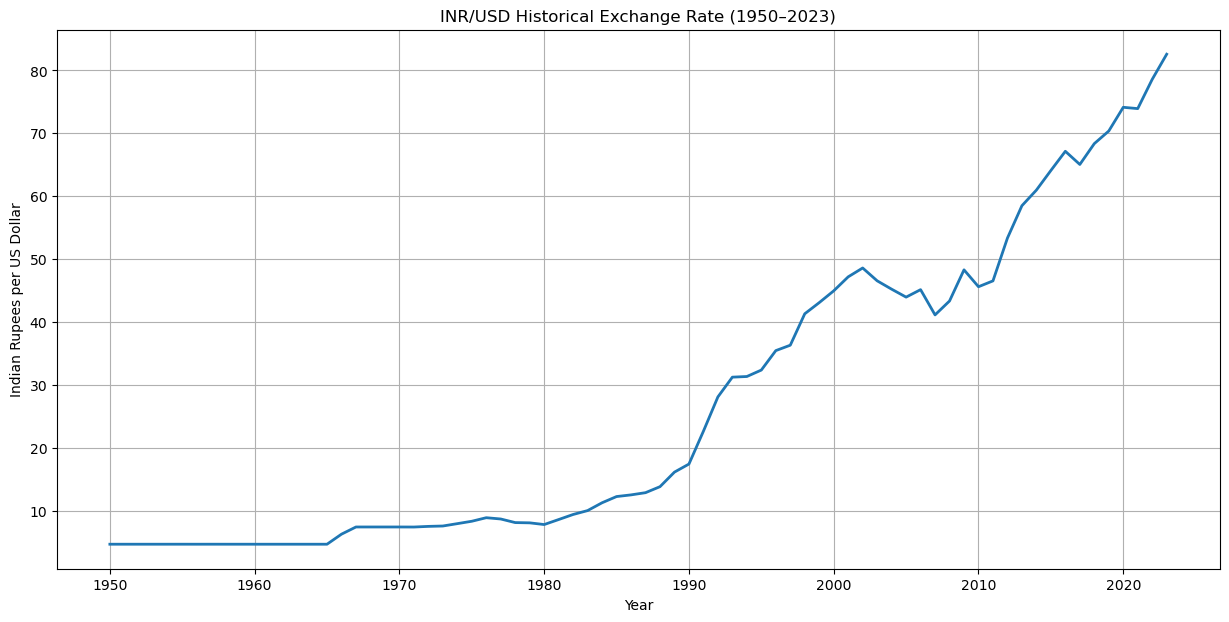

In [66]:
plt.figure(figsize=(15, 7))

plt.plot(
    historical_combined["Year"],
    historical_combined["INR_per_USD"],
    linewidth=2
)

plt.title("INR/USD Historical Exchange Rate (1950–2023)")
plt.xlabel("Year")
plt.ylabel("Indian Rupees per US Dollar")
plt.grid(True)
plt.show()

In [67]:
historical_combined.to_csv(
    "INR_USD_Historical_1950_2023.csv",
    index=False
)

print("Combined historical dataset saved successfully!")

Combined historical dataset saved successfully!


In [68]:
early_rbi = historical_df[
    historical_df["Year"].between(1947, 1949)
].copy()

display(early_rbi[
    ["Fiscal_Year", "INR_per_USD"]
])

,Fiscal_Year,INR_per_USD
0,1947-48,3.317500
1,1948-49,3.317500
2,1949-50,4.074375


In [69]:
# Select daily exchange rates for January–August 2024
data_2024 = exchange_rate[
    (exchange_rate["Date"] >= "2024-01-01") &
    (exchange_rate["Date"] <= "2024-08-31")
].copy()

# Calculate average exchange rate
average_2024 = data_2024["INR_per_USD"].mean()

print("Observations in Jan–Aug 2024:", len(data_2024))
print(f"Average INR/USD (Jan–Aug 2024): {average_2024:.4f}")

Observations in Jan–Aug 2024: 169
Average INR/USD (Jan–Aug 2024): 83.3563


In [70]:
# Add the partial-year observation
row_2024 = pd.DataFrame({
    "Year": [2024],
    "INR_per_USD": [average_2024],
    "Source": ["FRED DEXINUS"],
    "Period_Type": ["Jan–Aug Average"]
})

historical_final = pd.concat(
    [historical_combined, row_2024],
    ignore_index=True
).sort_values("Year")

display(historical_final.tail())

,Year,INR_per_USD,Source,Period_Type
70,2020,74.142920,FRED DEXINUS,Calendar Year
71,2021,73.935100,FRED DEXINUS,Calendar Year
72,2022,78.579160,FRED DEXINUS,Calendar Year
73,2023,82.570843,FRED DEXINUS,Calendar Year
74,2024,83.356272,FRED DEXINUS,Jan–Aug Average


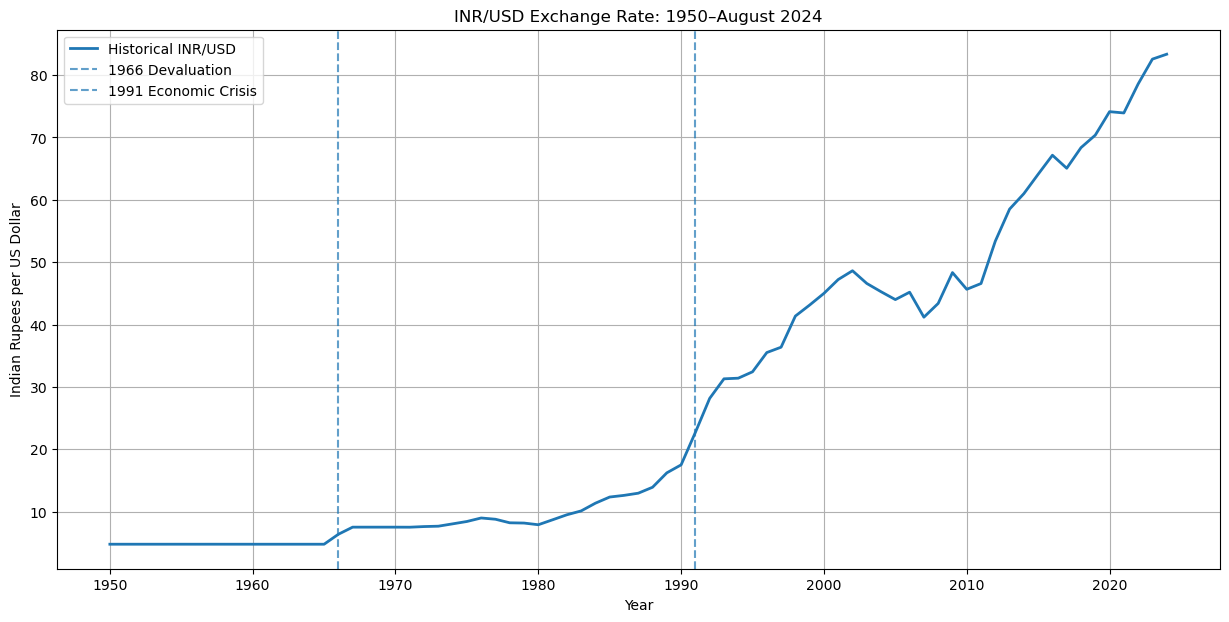

In [71]:
plt.figure(figsize=(15, 7))

plt.plot(
    historical_final["Year"],
    historical_final["INR_per_USD"],
    linewidth=2,
    label="Historical INR/USD"
)

plt.axvline(
    1966,
    linestyle="--",
    alpha=0.7,
    label="1966 Devaluation"
)

plt.axvline(
    1991,
    linestyle="--",
    alpha=0.7,
    label="1991 Economic Crisis"
)

plt.title("INR/USD Exchange Rate: 1950–August 2024")
plt.xlabel("Year")
plt.ylabel("Indian Rupees per US Dollar")
plt.legend()
plt.grid(True)
plt.show()

In [72]:
historical_final.to_csv(
    "INR_USD_Historical_1950_Aug2024.csv",
    index=False
)

print("Historical data saved successfully!")

Historical data saved successfully!


In [73]:
# Calculate 95% prediction intervals
forecast_interval = arima_forecast.conf_int(alpha=0.05)

# Add lower and upper bounds
forecast_df["ARIMA_Lower_95"] = forecast_interval.iloc[:, 0].to_numpy()
forecast_df["ARIMA_Upper_95"] = forecast_interval.iloc[:, 1].to_numpy()

display(
    forecast_df[
        ["Date", "ARIMA_Forecast", "ARIMA_Lower_95", "ARIMA_Upper_95"]
    ].tail()
)

,Date,ARIMA_Forecast,ARIMA_Lower_95,ARIMA_Upper_95
283,2050-04-01,95.29783,65.717645,124.878015
284,2050-05-01,95.29783,65.665499,124.930161
285,2050-06-01,95.29783,65.613444,124.982215
286,2050-07-01,95.29783,65.561481,125.034178
287,2050-08-01,95.29783,65.509609,125.086051


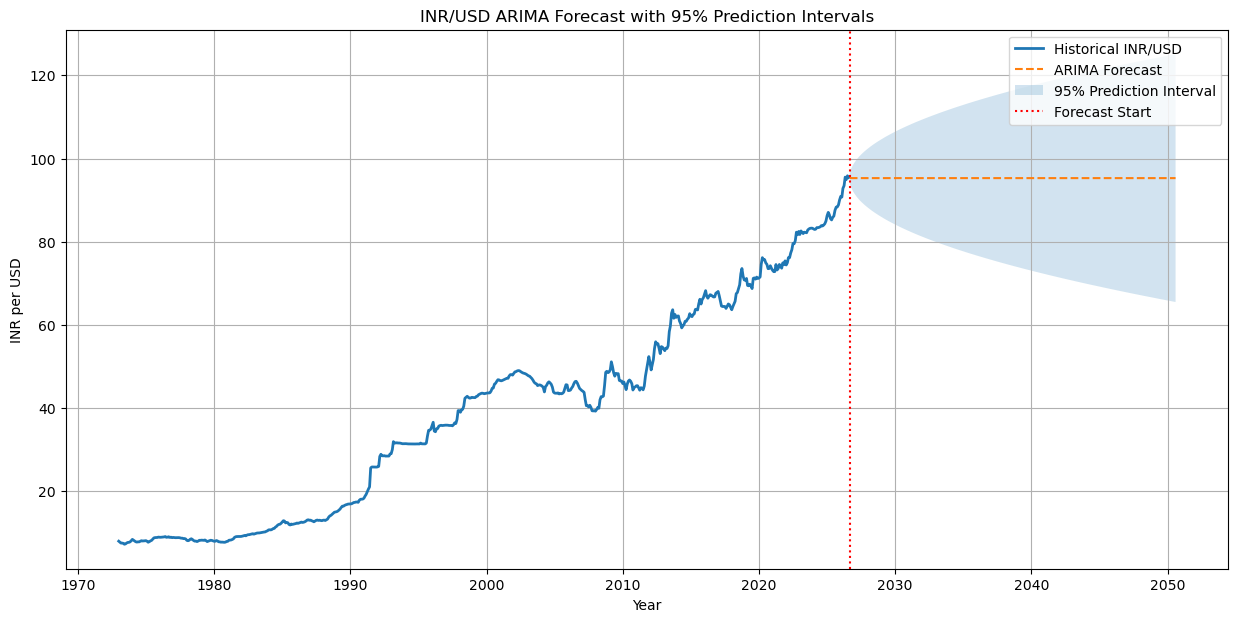

In [74]:
plt.figure(figsize=(15, 7))

# Historical observations
plt.plot(
    monthly.index,
    monthly.values,
    label="Historical INR/USD",
    linewidth=2
)

# ARIMA forecast
plt.plot(
    forecast_df["Date"],
    forecast_df["ARIMA_Forecast"],
    label="ARIMA Forecast",
    linestyle="--"
)

# Prediction interval
plt.fill_between(
    forecast_df["Date"],
    forecast_df["ARIMA_Lower_95"],
    forecast_df["ARIMA_Upper_95"],
    alpha=0.2,
    label="95% Prediction Interval"
)

plt.axvline(
    pd.Timestamp("2026-09-01"),
    linestyle=":",
    color="red",
    label="Forecast Start"
)

plt.title("INR/USD ARIMA Forecast with 95% Prediction Intervals")
plt.xlabel("Year")
plt.ylabel("INR per USD")
plt.legend()
plt.grid(True)
plt.show()

In [75]:
forecast_2050_interval = forecast_df.loc[
    forecast_df["Date"] == pd.Timestamp("2050-08-01"),
    [
        "ARIMA_Forecast",
        "ARIMA_Lower_95",
        "ARIMA_Upper_95"
    ]
]

display(forecast_2050_interval.round(2))

,ARIMA_Forecast,ARIMA_Lower_95,ARIMA_Upper_95
287,95.3,65.51,125.09


In [76]:
forecast_df.to_csv(
    "INR_USD_Forecast_2026_2050_With_Intervals.csv",
    index=False
)

print("Forecast with prediction intervals saved successfully!")

Forecast with prediction intervals saved successfully!


## Project Methodology

### Data Collection

This project uses historical INR/USD exchange-rate observations from the Federal Reserve Economic Data (FRED), Penn World Table 11.0, and historical Reserve Bank of India (RBI) publications.

Daily exchange-rate observations from FRED were aggregated into annual and monthly averages. Historical annual exchange-rate observations from Penn World Table were used to extend the analysis backward to 1950.

The project also uses World Bank inflation data, Forbes billionaire counts, and World Happiness Report scores to compare economic and social indicators in India and the United States.

### Data Preprocessing

The datasets were processed using Python and Pandas. Dates were converted into appropriate formats, missing values were handled, and observations were sorted chronologically.

Daily exchange-rate observations were converted into monthly averages for forecasting and annual averages for historical trend analysis.

The historical analysis uses observations through August 2024. The forecasting models use available monthly observations through August 2026.

### Forecasting Methods

Two forecasting methods were implemented:

**ARIMA (1,1,1):** A time-series model using autoregressive, differencing, and moving-average components.

**Linear Regression:** A statistical model that estimates a linear relationship between time and exchange-rate values.

Three illustrative depreciation scenarios were also developed using annual depreciation assumptions of 1%, 2.5%, and 4%.

### Model Evaluation

The forecasting models were trained on historical monthly observations through December 2018 and evaluated using January 2019–August 2024 observations.

Model accuracy was assessed using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

### Comparative Analysis

India and the United States were compared using annual consumer-price inflation, billionaire counts, and World Happiness Report scores.

The inflation analysis considered both average inflation and the standard deviation of annual inflation rates.

### Limitations

The historical exchange-rate dataset combines sources with potentially different methodologies. RBI fiscal-year observations from 1947–1949 remain provisional and are not included in the verified calendar-year chart.

The 2024 historical observation represents January–August rather than the full calendar year.

Long-term exchange-rate forecasts are subject to significant uncertainty. The ARIMA model does not explicitly incorporate future inflation, monetary policy, international trade, or geopolitical developments.

Billionaire counts and happiness scores represent different dimensions of economic and social conditions and should not be interpreted as direct causal measures of exchange-rate performance.

## References

1. Federal Reserve Bank of St. Louis. *Indian Rupees to One U.S. Dollar (DEXINUS).* Federal Reserve Economic Data (FRED). https://fred.stlouisfed.org/series/DEXINUS

2. Feenstra, R. C., Inklaar, R., and Timmer, M. P. *Penn World Table, Version 11.0.* Groningen Growth and Development Centre. https://www.rug.nl/ggdc/productivity/pwt/

3. Reserve Bank of India. *Historical Exchange Rates and Handbook of Statistics on the Indian Economy.* https://www.rbi.org.in/

4. World Bank. *Inflation, Consumer Prices (Annual %), Indicator FP.CPI.TOTL.ZG.* https://data.worldbank.org/indicator/FP.CPI.TOTL.ZG

5. Forbes. *The World's Billionaires, 2023 and 2024.* https://www.forbes.com/billionaires/

6. World Happiness Report. (2024). *World Happiness Report 2024.* https://worldhappiness.report/ed/2024/

In [77]:
early_rbi = historical_df[
    historical_df["Year"].between(1947, 1949)
].copy()

display(
    early_rbi[
        ["Fiscal_Year", "INR_per_USD"]
    ]
)

,Fiscal_Year,INR_per_USD
0,1947-48,3.317500
1,1948-49,3.317500
2,1949-50,4.074375


### Historical Data Coverage and Limitations

The project investigates INR/USD exchange-rate movements beginning in August 1947. However, the validated calendar-year series used for the principal historical chart begins in 1950.

Pre-1950 RBI fiscal-year exchange-rate observations were collected separately but require verification against the original published table, including the reporting period and exchange-rate units.

The project therefore distinguishes between its intended historical scope (August 1947–August 2024) and the verified annual data coverage (1950–August 2024). No missing observations were estimated or fabricated to extend the historical series.